# 04b – Bidirectional LSTM
`text → word IDs (150 steps) → Embedding (128-d) → BiLSTM → pooling → Dropout → Dense(8) + Softmax`; reads word order and learns word embeddings.

In [1]:
import os, sys, time, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import f1_score

from src.data import load_split, LABELS, SEED, RESULTS_DIR, ROOT as PROJECT_ROOT
from src.plotting import set_style, save, SERIES, TEXT, TEXT_SECONDARY
from src.evaluate import record_metrics, per_class_report, save_predictions, plot_confusion_matrix
from src.diagrams import draw_chain

set_style()
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

train, val, test = load_split("train"), load_split("val"), load_split("test")
label_to_id = {l: i for i, l in enumerate(LABELS)}
y_train, y_val, y_test = (d.label.map(label_to_id).to_numpy() for d in (train, val, test))
counts = np.bincount(y_train, minlength=len(LABELS))
class_weight = {i: len(y_train) / (len(LABELS) * c) for i, c in enumerate(counts)}

TensorFlow 2.21.0 | Keras 3.15.1


## 1. Text → word-ID sequences
150 words fully cover ~96% of tickets.

In [2]:
VOCAB_SIZE = 30_000
SEQ_LEN = 150
lengths = train.text.str.split().str.len()
print(f"Tickets fully covered by {SEQ_LEN} words: {(lengths <= SEQ_LEN).mean():.1%}")

vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_mode="int", output_sequence_length=SEQ_LEN, standardize=None)
vectorizer.adapt(tf.constant(train.text.values))
vocab = vectorizer.get_vocabulary()
N_WORDS = len(vocab)  # the training set has fewer distinct words than the 30k cap
print("Vocabulary size:", N_WORDS, "| index 0 = padding, 1 = unknown word")
example = train.text.iloc[3]
print("Example:", example[:90], "...")
print("IDs:    ", vectorizer(tf.constant([example])).numpy()[0][:15], "...")

def to_ds(df, y, shuffle=False, batch=64):
    ds = tf.data.Dataset.from_tensor_slices((df.text.values, y))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = to_ds(train, y_train, shuffle=True), to_ds(val, y_val), to_ds(test, y_test)

Tickets fully covered by 150 words: 95.8%


Vocabulary size: 11135 | index 0 = padding, 1 = unknown word
Example: proposal to be removed by it pm proposal removed by importance high dear colleagues experi ...
IDs:     [1407   29   32  497   25 1108    3 1407  497   25  102   74   19  251
  935] ...


## 2. Compare recurrent variants on validation

In [3]:
def trainable_params(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

def build_rnn(cell="lstm", pooling="max", units=64, emb_dim=128, dropout=0.4):
    inputs = keras.Input(shape=(), dtype="string", name="text")
    x = vectorizer(inputs)
    x = layers.Embedding(N_WORDS, emb_dim, mask_zero=True, name="embedding")(x)
    x = layers.SpatialDropout1D(0.2, name="embedding_dropout")(x)
    Cell = layers.LSTM if cell == "lstm" else layers.GRU
    x = layers.Bidirectional(Cell(units, return_sequences=(pooling == "max")), name=f"bi_{cell}")(x)
    if pooling == "max":
        x = layers.GlobalMaxPooling1D(name="max_pool")(x)
    x = layers.Dropout(dropout, name="dropout")(x)
    outputs = layers.Dense(len(LABELS), activation="softmax", name="softmax")(x)
    model = keras.Model(inputs, outputs, name=f"bi{cell}")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

CONFIGS = {
    "BiLSTM, last state": dict(cell="lstm", pooling="last"),
    "BiLSTM, max-pool": dict(cell="lstm", pooling="max"),
    "BiGRU, max-pool": dict(cell="gru", pooling="max"),
}
runs = {}
for name, cfg in CONFIGS.items():
    keras.utils.set_random_seed(SEED)
    model = build_rnn(**cfg)
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
    secs = time.time() - t0
    val_pred = model.predict(val_ds, verbose=0).argmax(1)
    runs[name] = dict(model=model, history=hist.history, seconds=secs, cfg=cfg,
                      val_macro_f1=f1_score(y_val, val_pred, average="macro"),
                      val_accuracy=(val_pred == y_val).mean(), params=trainable_params(model),
                      best_epoch=int(np.argmin(hist.history["val_loss"])) + 1, epochs_run=len(hist.history["loss"]))
    print(f"{name:20s} val macro-F1 {runs[name]['val_macro_f1']:.4f} | acc {runs[name]['val_accuracy']:.4f} | "
          f"best epoch {runs[name]['best_epoch']}/{runs[name]['epochs_run']} | {secs / 60:.1f} min", flush=True)

tuning = pd.DataFrame({k: {c: v[c] for c in ["val_macro_f1", "val_accuracy", "params", "best_epoch", "seconds"]}
                       for k, v in runs.items()}).T
tuning.to_csv(RESULTS_DIR / "bilstm_tuning.csv")
tuning

/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


BiLSTM, last state   val macro-F1 0.8450 | acc 0.8443 | best epoch 3/5 | 6.0 min


/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'max_pool' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


BiLSTM, max-pool     val macro-F1 0.8385 | acc 0.8445 | best epoch 2/4 | 4.4 min


/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'max_pool' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/chmo4618exc/ML_PROJECT/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


BiGRU, max-pool      val macro-F1 0.8413 | acc 0.8412 | best epoch 2/4 | 4.1 min


,val_macro_f1,val_accuracy,params,best_epoch,seconds
"BiLSTM, last state",0.844952,0.844331,1525128.0,3.0,358.378829
"BiLSTM, max-pool",0.838542,0.844473,1525128.0,2.0,263.359580
"BiGRU, max-pool",0.841283,0.841209,1500808.0,2.0,245.643397


In [4]:
best_name = max(runs, key=lambda k: runs[k]["val_macro_f1"])
best = runs[best_name]
rnn = best["model"]
print("Selected:", best_name)
rnn.summary()

Selected: BiLSTM, last state


Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 150)       │          0 │ text[0][0]        │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 150, 128)  │  1,425,280 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dropout   │ (None, 150, 128)  │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 150)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bi_lstm             │ (None, 128)       │     98,816 │ embedding_dropou… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bi_lstm[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Dense)     │ (None, 8)         │      1,032 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,575,386 (17.45 MB)

 Trainable params: 1,525,128 (5.82 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,050,258 (11.64 MB)

## 3. Architecture diagram

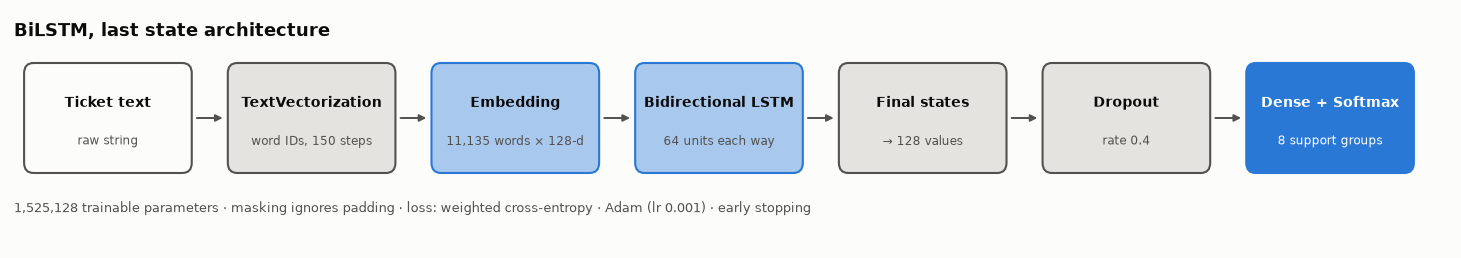

In [5]:
cfg = best["cfg"]
cell = cfg["cell"].upper()
chain = [("io", "Ticket text", "raw string"),
         ("prep", "TextVectorization", f"word IDs, {SEQ_LEN} steps"),
         ("layer", "Embedding", f"{N_WORDS:,} words × 128-d"),
         ("layer", f"Bidirectional {cell}", "64 units each way"),
         ("prep", "Global max-pool" if cfg["pooling"] == "max" else "Final states", "→ 128 values"),
         ("prep", "Dropout", "rate 0.4"),
         ("output", "Dense + Softmax", "8 support groups")]
fig = draw_chain(chain, f"{best_name} architecture", "15_bilstm_architecture",
                 subtitle=f"{trainable_params(rnn):,} trainable parameters · masking ignores padding · loss: weighted cross-entropy · Adam (lr 0.001) · early stopping")
plt.show()

## 4. Training curves

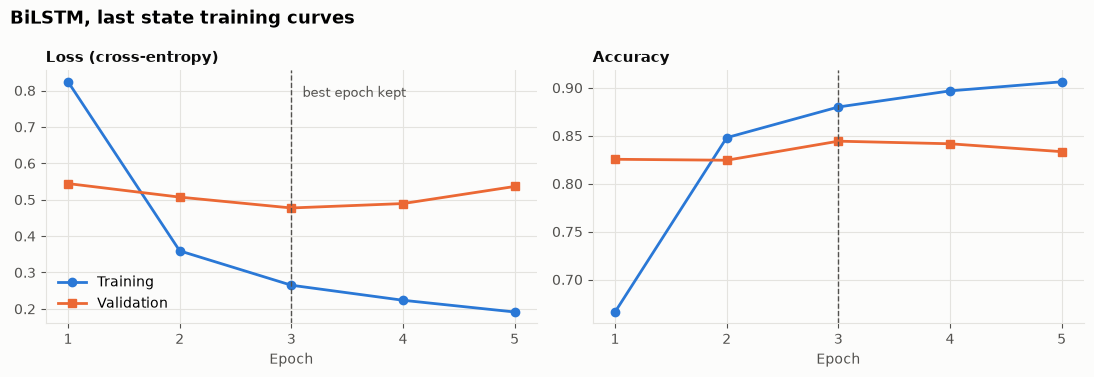

In [6]:
h = best["history"]
epochs = np.arange(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, lab in [(axes[0], "loss", "Loss (cross-entropy)"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(epochs, h[key], color="#2a78d6", marker="o", markersize=6, linewidth=2, label="Training")
    ax.plot(epochs, h[f"val_{key}"], color="#eb6834", marker="s", markersize=6, linewidth=2, label="Validation")
    ax.axvline(best["best_epoch"], color=TEXT_SECONDARY, linestyle="--", linewidth=1)
    ax.set_xlabel("Epoch")
    ax.set_title(lab, fontsize=11)
    ax.set_xticks(epochs)
axes[0].text(best["best_epoch"] + 0.1, axes[0].get_ylim()[1] * 0.95, "best epoch kept", fontsize=9, color=TEXT_SECONDARY, va="top")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle(f"{best_name} training curves", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "16_bilstm_training_curves")
plt.show()

## 5. Test results

In [7]:
val_proba = rnn.predict(val_ds, verbose=0)
test_proba = rnn.predict(test_ds, verbose=0)
val_pred = np.array(LABELS)[val_proba.argmax(1)]
test_pred = np.array(LABELS)[test_proba.argmax(1)]

extra = dict(params=trainable_params(rnn), train_seconds=round(best["seconds"], 1))
record_metrics("bilstm", "val", val.label, val_pred, **extra)
table = record_metrics("bilstm", "test", test.label, test_pred, **extra)
save_predictions("bilstm", test.text, test.label, test_proba)

PROJECT_ROOT.joinpath("models").mkdir(exist_ok=True)
rnn.save(PROJECT_ROOT / "models" / "bilstm.keras")
table[table.split == "test"].set_index("model").round(4)

,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,params,train_seconds
model,,,,,,,,
baseline_tfidf_lr,test,0.8609,0.8614,0.8632,0.8621,0.8613,1027488,12.3
ann_mlp,test,0.8470,0.8449,0.8491,0.8460,0.8476,12802312,185.0
bilstm,test,0.8324,0.8103,0.8563,0.8307,0.8327,1525128,358.4


In [8]:
rep = per_class_report(test.label, test_pred)
rep.to_csv(RESULTS_DIR / "per_class_bilstm.csv")
base = pd.read_csv(RESULTS_DIR / "per_class_baseline_tfidf_lr.csv", index_col=0)
ann = pd.read_csv(RESULTS_DIR / "per_class_ann_mlp.csv", index_col=0)
pd.DataFrame({"baseline F1": base.f1, "ANN F1": ann.f1, "BiLSTM F1": rep.f1,
              "BiLSTM − baseline": rep.f1 - base.f1}).reindex(LABELS).round(3)

,baseline F1,ANN F1,BiLSTM F1,BiLSTM − baseline
Hardware,0.852,0.838,0.820,-0.032
HR Support,0.870,0.857,0.836,-0.034
Access,0.887,0.880,0.877,-0.010
Miscellaneous,0.827,0.812,0.807,-0.019
Storage,0.899,0.889,0.853,-0.046
Purchase,0.913,0.904,0.890,-0.023
Internal Project,0.870,0.839,0.830,-0.040
Administrative rights,0.780,0.748,0.733,-0.047


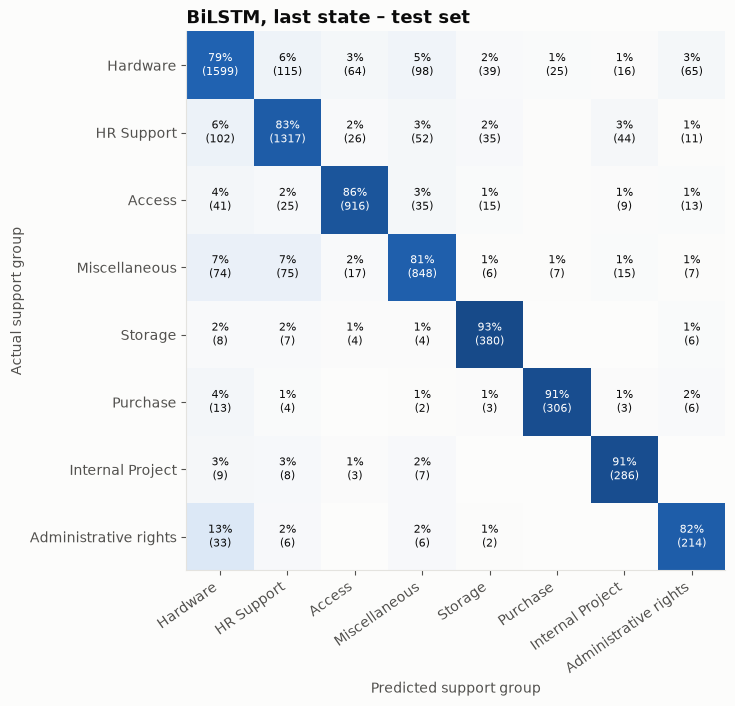

In [9]:
fig, cm = plot_confusion_matrix(test.label, test_pred, f"{best_name} – test set", "17_bilstm_confusion_matrix")
plt.show()

## 6. Learned word embeddings
Nearest neighbours by cosine similarity.

In [10]:
emb = rnn.get_layer("embedding").get_weights()[0]
emb_n = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-9)
word_to_id = {w: i for i, w in enumerate(vocab)}
rows = []
for w in ["laptop", "password", "folder", "po", "outlook", "timecard", "monitor", "license"]:
    if w in word_to_id:
        sims = emb_n @ emb_n[word_to_id[w]]
        nn_ids = [i for i in np.argsort(-sims) if i not in (0, 1, word_to_id[w])][:6]
        rows.append({"word": w, "nearest words": ", ".join(vocab[i] for i in nn_ids)})
pd.DataFrame(rows)

,word,nearest words
0,laptop,"monitor, connection, adaptors, backpack, certi..."
1,password,"confluence, user, glide, license, passwords, l..."
2,folder,"mailbox, folders, size, storage, accept, shared"
3,po,"purchase, device, allocation, replenishment, i..."
4,outlook,"exchange, upgrade, upgrading, windows, keeps, ..."
5,timecard,"internship, starter, forwarder, annual, leave,..."
6,monitor,"bag, charger, certificate, calls, adaptor, bac..."
7,license,"confluence, licence, locked, reset, studio, li..."


## 7. Sanity check on new tickets

In [11]:
from src.preprocess import clean_text
reloaded = keras.models.load_model(PROJECT_ROOT / "models" / "bilstm.keras")
demo = ["My laptop screen is flickering and the docking station does not detect the monitor",
        "Please raise a PO for two new headsets, purchase approved by my manager",
        "I cannot open Confluence, it says my account has no access",
        "Please increase the size of my shared folder, it is full"]
p = reloaded.predict(tf.constant([clean_text(t) for t in demo]), verbose=0)
pd.DataFrame({"ticket": demo, "prediction": np.array(LABELS)[p.argmax(1)], "confidence": p.max(1).round(3)})

,ticket,prediction,confidence
0,My laptop screen is flickering and the docking...,Hardware,0.997
1,"Please raise a PO for two new headsets, purcha...",Purchase,0.997
2,"I cannot open Confluence, it says my account h...",Access,0.997
3,"Please increase the size of my shared folder, ...",Storage,1.000
